# Support Vector Regression

## Phase 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR

from datetime import datetime

from sqlalchemy.dialects.postgresql import JSONB
from sqlalchemy import create_engine

In [2]:
# Importing the dataset and loading it into postgreSQL
engine = create_engine("postgresql+psycopg2://postgres@localhost:5432/postgres")

df = pd.read_excel("Concrete_Data.xls", na_values="?")
df.columns = ["cement", "blast_furnace_slag", "fly_ash", "water", "superplasticizer", "coarse_aggregate", "fine_aggregate", "age", "compressive_strength"]
df.to_sql("concrete", engine, if_exists="replace", index=False)
pd.read_sql("select count(*) from concrete", engine)

,count
0,1030


In [3]:
df.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [5]:
currated_list = []

for col in df.columns:
    res = pd.read_sql(f"select count({col}) as n, avg({col}) as mean, stddev({col}) as std, min({col}) as min, max({col}) as max, percentile_cont(0.5) within group (order by {col}) as median from concrete", engine)
    currated_list.append(res)
    print(res)
    print(col)

currated_table =pd.concat(currated_list, keys=df.columns, axis=0)

      n        mean         std    min    max  median
0  1030  281.165631  104.507142  102.0  540.0   272.9
cement
      n       mean        std  min    max  median
0  1030  73.895485  86.279104  0.0  359.4    22.0
blast_furnace_slag
      n       mean        std  min    max  median
0  1030  54.187136  63.996469  0.0  200.1     0.0
fly_ash
      n        mean        std     min    max  median
0  1030  181.566359  21.355567  121.75  247.0   185.0
water
      n      mean       std  min   max  median
0  1030  6.203112  5.973492  0.0  32.2    6.35
superplasticizer
      n        mean        std    min     max  median
0  1030  972.918592  77.753818  801.0  1145.0   968.0
coarse_aggregate
      n        mean        std    min    max  median
0  1030  773.578883  80.175427  594.0  992.6  779.51
fine_aggregate
      n       mean        std  min  max  median
0  1030  45.662136  63.169912    1  365    28.0
age
      n       mean        std       min        max     median
0  1030  35.817836  16.70

In [6]:
currated_table

,,n,mean,std,min,max,median
cement,0,1030,281.165631,104.507142,102.000000,540.000000,272.900000
blast_furnace_slag,0,1030,73.895485,86.279104,0.000000,359.400000,22.000000
fly_ash,0,1030,54.187136,63.996469,0.000000,200.100000,0.000000
water,0,1030,181.566359,21.355567,121.750000,247.000000,185.000000
superplasticizer,0,1030,6.203112,5.973492,0.000000,32.200000,6.350000
coarse_aggregate,0,1030,972.918592,77.753818,801.000000,1145.000000,968.000000
fine_aggregate,0,1030,773.578883,80.175427,594.000000,992.600000,779.510000
age,0,1030,45.662136,63.169912,1.000000,365.000000,28.000000
compressive_strength,0,1030,35.817836,16.705679,2.331808,82.599225,34.442774


In [7]:
# query to get strenght by age
query = """
select avg(compressive_strength) as avg_strength, count(*) as n, case when age <= 7 then 'new' when age > 7 and age <= 28 then 'intermediate' when age > 28 and age <= 90 then 'old' else 'very old' end as age_bucket from concrete group by age_bucket order by min(age)"""

pd.read_sql(query, engine)

,avg_strength,n,age_bucket
0,22.308202,262,new
1,35.730325,487,intermediate
2,47.641098,145,old
3,49.551428,136,very old


In [8]:
# query to get water/cement ratio
query = """
select case when water/cement < 0.4 then 'low' when water/cement >= 0.4 and water/cement <= 0.6 then 'medium' else 'high' end as w_c_ratio, avg(compressive_strength) as avg_strength, count(*) as n from concrete group by w_c_ratio order by min(water/cement)"""
pd.read_sql(query, engine)



,w_c_ratio,avg_strength,n
0,low,56.263799,99
1,medium,42.443606,319
2,high,29.056772,612


In [9]:
df["wc_ratio"] = df["water"]/df["cement"]
df['wc_ratio'].describe()

count    1030.000000
mean        0.748269
std         0.314005
min         0.266893
25%         0.533333
50%         0.675349
75%         0.935014
max         1.882353
Name: wc_ratio, dtype: float64

In [10]:
df["compressive_strength"] = df.pop("compressive_strength")

## Phase 2

In [11]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
print(X_train.shape)
print(X_test.shape)

(824, 9)
(206, 9)


### Baseline MLR

In [13]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred = mlr.predict(X_test)

rmse_mlr = np.sqrt(mean_squared_error(y_test, y_pred))
mae_mlr = mean_absolute_error(y_test, y_pred)
r2_mlr = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_mlr}")
print(f"MAE: {mae_mlr}")
print(f"R2: {r2_mlr}")

RMSE: 9.729454263398877
MAE: 7.638187592298282
R2: 0.6326378432975657


...:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
...:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
...:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


### Baseline Poly degree = 2

In [14]:
poly_reg = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])
poly_reg.fit(X_train, y_train)

y_pred = poly_reg.predict(X_test)

rmse_poly2 = np.sqrt(mean_squared_error(y_test, y_pred))
mae_poly2 = mean_absolute_error(y_test, y_pred)
r2_poly2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_poly2}")
print(f"MAE: {mae_poly2}")
print(f"R2: {r2_poly2}")

RMSE: 7.384739893851982
MAE: 5.928598467454061
R2: 0.7883648206266642


...:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
...:293: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
...:293: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


### Logging baselines models to model_results

In [15]:
model_results = pd.DataFrame({
    'project': 'p4_concrete',
    'model': ['linear_concrete', 'poly2_concrete'],
    'params': [{"feature": 9, "degree": 1}, {"feature": 9, "degree": 2, "scaled": 'true'}],
    'rmse': [rmse_mlr, rmse_poly2], 'mae': [mae_mlr, mae_poly2], 'r2': [r2_mlr, r2_poly2],
    'run_at': datetime.now(),
})
#model_results.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

## Phase 3

#### Unscaled SVR

In [16]:
unscaled_svr_rbf = SVR(kernel="rbf")
unscaled_svr_rbf.fit(X_train, y_train)
y_pred = unscaled_svr_rbf.predict(X_test)

rmse_unscaled_svr_rbf = np.sqrt(mean_squared_error(y_test, y_pred))
mae_unscaled_svr_rbf = mean_absolute_error(y_test, y_pred)
r2_unscaled_svr_rbf = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_unscaled_svr_rbf}")

RMSE: 14.159005761372415


#### Scaled SVR rbf

In [17]:
scaled_svr_default = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])
scaled_svr_default.fit(X_train, y_train)
y_pred = scaled_svr_default.predict(X_test)

rmse_scaled_svr_default = np.sqrt(mean_squared_error(y_test, y_pred))
mae_scaled_svr_default = mean_absolute_error(y_test, y_pred)
r2_scaled_svr_default = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_scaled_svr_default}")

RMSE: 9.374641389947772


#### Scaled SVR linear

In [18]:
scaled_svr_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="linear"))
])
scaled_svr_linear.fit(X_train, y_train)
y_pred = scaled_svr_linear.predict(X_test)

rmse_scaled_svr_linear = np.sqrt(mean_squared_error(y_test, y_pred))
mae_scaled_svr_linear = mean_absolute_error(y_test, y_pred)
r2_scaled_svr_linear = r2_score(y_test, y_pred)

print(f"RMSE: {rmse_scaled_svr_linear}")

RMSE: 10.875238543297902


In [19]:
model_results = pd.DataFrame({
    'project': 'p4_concrete',
    'model': ['unscaled_svr_rbf', 'scaled_svr_default', 'scaled_svr_linear'],
    'params': [
        {"kernel": "rbf", "scaled": False, "C": 1, "epsilon": 0.1, "gamma": "scale", "features": 9},
        {"kernel": "rbf", "scaled": True, "C": 1, "epsilon": 0.1, "gamma": "scale", "features": 9},
        {"kernel": "linear", "scaled": True, "C": 1, "epsilon": 0.1, "features": 9},],
    'rmse': [rmse_unscaled_svr_rbf, rmse_scaled_svr_default, rmse_scaled_svr_linear ], 
    'mae': [mae_unscaled_svr_rbf, mae_scaled_svr_default, mae_scaled_svr_linear], 
    'r2': [r2_unscaled_svr_rbf, r2_scaled_svr_default, r2_scaled_svr_linear],
    'run_at': datetime.now(),
})
#model_results.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

In [20]:
scaled_svr_default_tuned = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_grid = {
    'svr__C': [1000, 3000],
    'svr__epsilon': [2, 3],
    'svr__gamma': [0.02, 0.05]
}

grid_search = GridSearchCV(scaled_svr_default_tuned, param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svr__C': [1000, 3000], 'svr__epsilon': [2, 3], 'svr__gamma': [0.02, 0.05]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is disp

In [21]:
grid_search.best_params_

{'svr__C': 1000, 'svr__epsilon': 3, 'svr__gamma': 0.05}

In [22]:
grid_search.best_score_

np.float64(-5.9587041156109235)

In [23]:
y_pred_tuned = grid_search.predict(X_test)
rmse_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
mae_tuned = mean_absolute_error(y_test, y_pred_tuned)
r2_tuned = r2_score(y_test, y_pred_tuned)

print(f"RMSE: {rmse_tuned}")
print(f"MAE: {mae_tuned}")
print(f"R2: {r2_tuned}")

RMSE: 5.840270621456649
MAE: 4.194069575763077
R2: 0.8676318810038838


In [24]:
model_results = pd.DataFrame({
    'project': 'p4_concrete',
    'model': ['svr_rbf_tuned'],
    'params': [
        {"kernel": "rbf", "scaled": True, "C": 1000, "epsilon": 3, "gamma": 0.05, "features": 9, "tuned": "GridSearchCV 5-fold"}],
    'rmse': [rmse_tuned], 
    'mae': [mae_tuned], 
    'r2': [r2_tuned],
    'run_at': datetime.now(),
})
#model_results.to_sql("model_results", engine, if_exists="append", index=False, dtype={"params": JSONB})

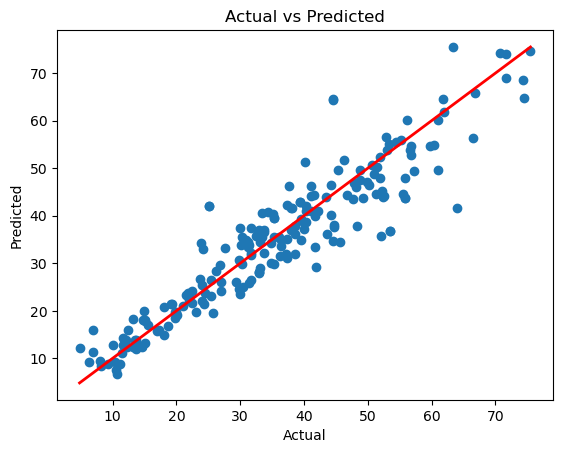

In [25]:
plt.scatter(y_test, y_pred_tuned)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted')
plt.savefig('svr_rbf_tuned.png')
plt.show()


### Heatmap

In [26]:
cv_results_df = pd.DataFrame(grid_search.cv_results_)
cv_results_df = cv_results_df[['param_svr__C', 'param_svr__epsilon', 'param_svr__gamma', 'mean_test_score']]
cv_results_df.columns = ['C', 'epsilon', 'gamma', 'RMSE']

cv_results_df =cv_results_df[cv_results_df['epsilon'] == 3]
cv_results_df['RMSE'] = -cv_results_df['RMSE']
cv_results_df = cv_results_df.sort_values(by='RMSE', ascending=True)

cv_results_df


,C,epsilon,gamma,RMSE
3,1000,3,0.05,5.958704
6,3000,3,0.02,5.970061
7,3000,3,0.05,6.131266
2,1000,3,0.02,6.279779


In [27]:
param_grid_1 = {
    'svr__C': [0.1, 1, 10, 100, 1000],
    'svr__epsilon': [3],
    'svr__gamma': [0.001, 0.01, 0.05, 0.1, 1]
}

grid_heatmap = GridSearchCV(scaled_svr_default_tuned, param_grid_1, cv=5, scoring='neg_root_mean_squared_error')
grid_heatmap.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svr', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svr__C': [0.1, 1, ...], 'svr__epsilon': [3], 'svr__gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is 

In [28]:
len(grid_heatmap.cv_results_['params'])

25

In [29]:
cv_results_df_1 = pd.DataFrame(grid_heatmap.cv_results_)
cv_results_df_1 = cv_results_df_1[['param_svr__C', 'param_svr__epsilon', 'param_svr__gamma', 'mean_test_score']]
cv_results_df_1.columns = ['C', 'epsilon', 'gamma', 'RMSE']

cv_results_df_1['RMSE'] = -cv_results_df_1['RMSE']
cv_results_df_1 = cv_results_df_1.sort_values(by='RMSE', ascending=True)
cv_results_df_1.drop(columns=['epsilon'], inplace=True)

cv_results_df_1

,C,gamma,RMSE
22,1000.0,0.050,5.958704
23,1000.0,0.100,6.165031
18,100.0,0.100,6.268274
17,100.0,0.050,6.399121
21,1000.0,0.010,7.105331
13,10.0,0.100,7.391996
19,100.0,1.000,7.607605
12,10.0,0.050,7.776909
16,100.0,0.010,7.881453
24,1000.0,1.000,7.892791


In [30]:
cv_results_df_1.pivot(index='C', columns='gamma', values='RMSE')

gamma,0.001,0.010,0.050,0.100,1.000
C,,,,,
0.1,16.790597,16.157234,15.281770,15.251591,16.530132
1.0,16.027312,12.807281,10.402838,10.280182,14.415516
10.0,12.596228,9.229185,7.776909,7.391996,9.617657
100.0,10.449725,7.881453,6.399121,6.268274,7.607605
1000.0,8.949359,7.105331,5.958704,6.165031,7.892791


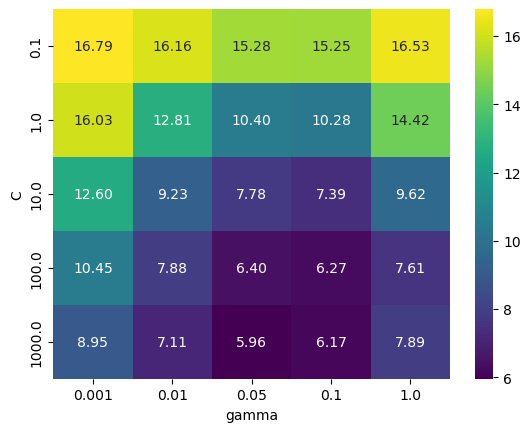

In [31]:
heatmap =  sns.heatmap(cv_results_df_1.pivot(index='C', columns='gamma', values='RMSE'), annot=True, fmt='.2f', cmap='viridis')
heatmap.figure.savefig('heatmap.png')
